## Setup

In [1]:
# import basic packages
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import PIL
import torch


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sumn2u/garbage-classification-v2")

print("Path to dataset files:", path)

C:\Users\pedro\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\pedro\.cache\kagglehub\datasets\sumn2u\garbage-classification-v2\versions\12


In [3]:
from datasets import load_dataset
dataset = load_dataset(path + "/standardized_384", split="train")

labels = dataset.features["label"].names
print(f"Labels: {labels}")
print(f"Number of images: {dataset.num_rows}")

Labels: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']
Number of images: 12259


In [4]:
labels_dict = dict(enumerate(labels))
label_name_selection = ['biological', 'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
label_num_selction  = [k for k, v in labels_dict.items() if v in label_name_selection]
print(f'Labels selected:\n {label_num_selction}')

Labels selected:
 [1, 2, 4, 5, 6, 7, 9]


In [6]:
#Objective Filtering: Biological, Cardboard, Glass, metal, paper, plastic & trash 
cut_dataset = dataset.filter(lambda x: x["label"] in label_num_selction)
print(f"Number of images: {cut_dataset.num_rows}")

Number of images: 8162


In [7]:
# Load CLIP processor and model
from transformers import CLIPProcessor, CLIPModel

processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 16621.86it/s]


## Image Exploration

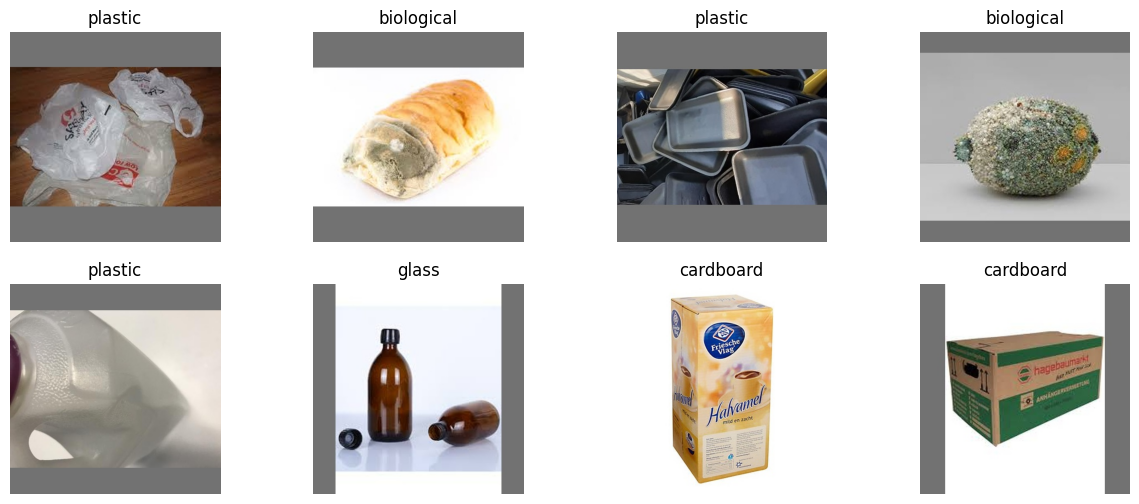

In [21]:
sample = cut_dataset.shuffle(seed=42)[:8]
images = sample["image"]
true_labels = sample["label"]

plt.figure(figsize=(15, 6))
for i, image in enumerate(images):
        plt.subplot(2, int(len(images)/2), i + 1)
        plt.imshow(image)
        plt.title(labels[true_labels[i]]) # adding title to the images for more informative plot
        plt.axis('off') #elimitating axis in plot for a cleaner view 

## Building a Machine Learning Model using CLIP encoder

In [ ]:
## function definition to build a pandas dataframe to have a clean visualization of the encoded images
from typing import List
def dataframe_construction(images_list: List, labels: List, processor=processor) -> pd.DataFrame:
    """
    Encode de images and build a dataframe with the image vector and the label.

    Parameters
    ----------
    images : List
        A list of images to be classified
    labels : List
        A list containing the possible classes
    processor
        The processor to be used to transform images (Only images) into numerical embeddings
   
    Returns
    -------
    encoded_df : dataframe
       A dataframe with the encoded vector and a target class
    """
    inputs = processor(images = images_list, return_tensors = 'pt')

    with torch.no_grad():
        image_features = model.get_image_features(**inputs) #extracting embeddings 

      

    encoded_df = pd.DataFrame(image_features.pooler_output.numpy())
    encoded_df['Class'] = labels

    return encoded_df        

In [ ]:
image_tabular_df = dataframe_construction(images_list=images, labels=true_labels)
image_tabular_df #high dimensional dataframe would need dim reduction techniques 

,0,1,2,3,4,5,6,7,8,9,...,503,504,505,506,507,508,509,510,511,Class
0,0.385403,0.330217,-0.319396,0.077163,0.285649,0.210489,0.031950,-0.023222,0.732212,0.323791,...,0.611634,0.074747,-0.038582,0.391598,-0.030099,-0.132654,0.824845,-0.283732,0.183326,7
1,0.291391,-0.035465,-0.517097,0.346682,0.319923,0.015897,0.013672,0.397592,0.703631,0.483648,...,0.071754,-0.119231,-0.153326,0.063566,-0.101361,-0.135940,0.315437,0.073204,0.352188,1
2,-0.062488,0.445819,-0.131140,0.033591,0.513944,0.467884,0.123465,0.978249,0.187948,0.041249,...,-0.005641,0.524330,-0.094177,-0.668705,0.160043,-0.238452,0.654642,-0.381224,-0.027717,7
3,0.588521,0.106470,-0.170277,-0.306561,0.201644,-0.281877,0.073513,0.583533,0.276892,0.206228,...,0.047167,0.118734,0.005894,-0.001646,-0.042736,-0.203006,0.138059,-0.101595,-0.150449,1
4,-0.382113,0.211972,0.003955,0.079801,0.696114,0.019814,0.206577,0.957801,0.420674,0.208012,...,0.179751,0.229463,-0.375621,-0.191220,-0.022807,0.138000,0.540686,0.329020,0.066278,7
5,-0.279161,0.634503,-0.067987,0.236658,0.678794,0.119458,0.101688,-0.570945,0.038354,0.186623,...,0.167057,0.641784,-0.208958,-0.275025,-0.375677,-0.232932,1.070237,-0.066520,-0.450291,4
6,-0.010758,-0.303045,0.133013,0.830612,0.310427,0.050393,0.313459,-0.006810,-0.052821,-0.125024,...,0.552211,0.042988,0.120125,-0.243519,0.300672,0.192334,0.393266,-0.159707,0.015447,2
7,0.044977,-0.032118,0.083641,-0.374866,0.198100,0.009476,0.183591,0.561323,-0.038868,0.322788,...,-0.057433,0.464527,0.135409,-0.206928,0.338395,-0.301519,0.439257,-0.073055,-0.108314,2


### Testing with higher sample to evaluate PCA

In [37]:
sample_PCA = cut_dataset.shuffle(seed=42)[:1000]
images_PCA = sample_PCA["image"]
true_labels_PCA = sample_PCA["label"]